In [1]:
pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 25.1 MB/s  0:00:01m0:00:0100:01
Note: you may need to restart the kernel to use updated packages.


# All the imports needed

In [2]:
import numpy as np
import pandas as pd
import seaborn as sn
import json
import os
import random
from matplotlib import pyplot as plt
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from joblib import Parallel, delayed
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import LabelEncoder, label_binarize
from torch.utils.data import Dataset, DataLoader, TensorDataset, WeightedRandomSampler
import torch.nn.functional as F
from sklearn.manifold import TSNE
from sklearn.metrics import (jaccard_score, accuracy_score, average_precision_score,
                             confusion_matrix, matthews_corrcoef,
                             precision_recall_curve,
                             precision_recall_fscore_support, roc_auc_score,
                             roc_curve)
from tqdm import tqdm
import ast
import seaborn as sns
import re
from dataclasses import dataclass

In [3]:
df = pd.read_pickle("/kaggle/input/datasets/rawanmahmoudrm/drug-info-with-embedding-drkg/drug_info_with_embedding_drkg.pkl")
ddi_df = pd.read_excel("/kaggle/input/datasets/rawanmahmoudrm/drug-interaction/df_interaction.xlsx", engine='openpyxl')
event_df = pd.read_excel("/kaggle/input/datasets/rawanmahmoudrm/drug-event/df_event.xlsx", engine='openpyxl')

In [4]:
df.head()

,index,id,target,enzyme,pathway,smile,name,sub_drkg_embedding
0,0,DB01296,P14780|Q00653|P01375|P01579|P33673,P33261|P05181,hsa:4318|hsa:4791|hsa:7124|hsa:3458,N[C@H]1C(O)O[C@H](CO)[C@@H](O)[C@@H]1O,Glucosamine,"[-0.0040870532, 0.0070311977, -0.018138904, 0...."
1,1,DB09230,Q02641,P08684,hsa:782,CC(C)OC(=O)C1=C(C)NC(N)=C(C1C1=CC=CC(=C1)[N+](...,Azelnidipine,"[0.0167142, -0.0058711586, 0.0006436159, -0.01..."
2,2,DB05812,P05093,P08684|Q06520|P10635|P10632|P05177|P33261|P11712,hsa:1586,[H][C@@]12CC=C(C3=CC=CN=C3)[C@@]1(C)CC[C@@]1([...,Abiraterone,"[0.05736915, -0.043914728, -0.040383797, -0.05..."
3,3,DB01195,Q14524|P35499|Q12809,P10635|P11712,hsa:6331|hsa:6329|hsa:3757,FC(F)(F)COC1=CC(C(=O)NCC2CCCCN2)=C(OCC(F)(F)F)...,Flecainide,"[0.0033631423, -0.0043699592, 0.0034768684, 0...."
4,4,DB00201,P30542|P29274|Q07343|P21817|BE0004922|P78527|O...,P20815|P05177|P24462|P08684|P05181|P10632|P117...,hsa:134|hsa:135|hsa:5142|hsa:6261|hsa:5591|hsa...,CN1C=NC2=C1C(=O)N(C)C(=O)N2C,Caffeine,"[0.0035572278, 0.015751174, 0.005466048, 0.005..."


In [5]:
df.dtypes

index                  int64
id                    object
target                object
enzyme                object
pathway               object
smile                 object
name                  object
sub_drkg_embedding    object
dtype: object

In [6]:
df.isnull().sum()

index                 0
id                    0
target                0
enzyme                0
pathway               0
smile                 0
name                  0
sub_drkg_embedding    0
dtype: int64

# Transforming the Drug_info data into vectors

In [7]:
for column in df.columns:
    try:
        if df[column].is_unique:
            print(f"{column}: All values are unique")
        else:
            print(f"{column}: Contains duplicates")
    except TypeError:
        print(f"{column}: Skipped (contains unhashable types like arrays)")

index: All values are unique
id: All values are unique
target: Contains duplicates
enzyme: Contains duplicates
pathway: Contains duplicates
smile: All values are unique
name: All values are unique
sub_drkg_embedding: Skipped (contains unhashable types like arrays)


In [8]:
def get_unique(df, column):
    features = set()
    for item in df[column].str.split('|'):
        features.update(item)
    return sorted(features) 

In [9]:
def to_vector(feature_str, unique_values, vector_size):
    values = feature_str.split('|')
    vector = np.zeros(vector_size)
    for i in values:
        if i in unique_values:
            index = unique_values.index(i)
            vector[index] = 1
    return vector

In [10]:
def preprocess_column(df, column_name):
    unique_values = get_unique(df, column_name)
    vector_size = len(unique_values)
    vectors = df[column_name].apply(
        lambda x: to_vector(x, unique_values, vector_size)
    )
    
    column_df = pd.DataFrame(
        vectors.tolist(), 
        columns=[f'{column_name}_{i}' for i in range(vector_size)]
    )
    
    result_df = pd.concat([df, column_df], axis=1)
    
    return result_df, unique_values

In [11]:
df, column_vec_T = preprocess_column(df, 'target')
df, column_vec_E = preprocess_column(df, 'enzyme')
df, column_vec_P = preprocess_column(df, 'pathway')

In [12]:
print("Vector size:", df.shape[1] - len(df.columns) + len(column_vec_T))
print("Vector size:", df.shape[1] - len(df.columns) + len(column_vec_E))
print("Vector size:", df.shape[1] - len(df.columns) + len(column_vec_P))

Vector size: 1162
Vector size: 202
Vector size: 957


In [13]:
df.drop('enzyme',axis= 'columns',inplace= True)
df.drop('target',axis= 'columns',inplace= True)
df.drop('pathway',axis= 'columns',inplace= True)

In [14]:
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)

fingerprints = []
for smiles in df['smile']:
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles else None
    if mol is not None:
        fingerprints.append(morgan_gen.GetFingerprintAsNumPy(mol).astype(np.uint8))
    else:
        print(f"Invalid or missing SMILES: {smiles}")
        fingerprints.append(np.zeros(1024, dtype=np.uint8)) 

fingerprints_df = pd.DataFrame(fingerprints, columns=[f"smile_{i}" for i in range(1024)])

df = pd.concat([df.drop(columns=['smile']), fingerprints_df], axis=1)

df.reset_index(drop=True, inplace=True)

df

,index,id,name,sub_drkg_embedding,target_0,target_1,target_2,target_3,target_4,target_5,...,smile_1014,smile_1015,smile_1016,smile_1017,smile_1018,smile_1019,smile_1020,smile_1021,smile_1022,smile_1023
0,0,DB01296,Glucosamine,"[-0.0040870532, 0.0070311977, -0.018138904, 0....",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
1,1,DB09230,Azelnidipine,"[0.0167142, -0.0058711586, 0.0006436159, -0.01...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
2,2,DB05812,Abiraterone,"[0.05736915, -0.043914728, -0.040383797, -0.05...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
3,3,DB01195,Flecainide,"[0.0033631423, -0.0043699592, 0.0034768684, 0....",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,1,0,0,0,0
4,4,DB00201,Caffeine,"[0.0035572278, 0.015751174, 0.005466048, 0.005...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
567,567,DB01587,Ketazolam,"[-0.0056434316, 0.012367835, -0.0029512532, 0....",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
568,568,DB00448,Lansoprazole,"[-0.005383134, -0.016868522, -0.00870955, -0.0...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
569,569,DB00559,Bosentan,"[0.0012874535, 0.010154434, 0.0002307562, -0.0...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
570,570,DB04953,Ezogabine,"[-0.011976738, -0.01062969, -0.0012158273, 0.0...",0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [15]:
print("Vector size:", df.shape[1] - len(df.columns) + len(fingerprints_df))

Vector size: 572


In [16]:
vector_size = fingerprints_df.shape[1]
print(f"Vector size: {vector_size}")

Vector size: 1024


# jaccard Similarity Matrix

In [17]:
def compute_jaccard_similarity(df, feature_prefix, save_path=None):
    
    selected_features = [col for col in df.columns if col.startswith(feature_prefix)]
    X = df[selected_features].values
    num_drugs = X.shape[0]

    jaccard_matrix = np.zeros((num_drugs, num_drugs))

    for i in tqdm(range(num_drugs), desc=f"Calculating Jaccard for {feature_prefix}"):
        for j in range(num_drugs):
            if np.sum(X[i]) == 0 and np.sum(X[j]) == 0:
                jaccard_matrix[i, j] = 1.0
            else:
                jaccard_matrix[i, j] = jaccard_score(X[i], X[j])

    jaccard_df = pd.DataFrame(jaccard_matrix, index=df["id"], columns=df["id"])
    
    if save_path:
        jaccard_df.to_csv(save_path)
        print(f"Saved Jaccard matrix for {feature_prefix} to {save_path}")
    
    return jaccard_df

In [18]:
jaccard_target = compute_jaccard_similarity(df, "target_", "/kaggle/working/jaccard_target.csv")
jaccard_enzyme = compute_jaccard_similarity(df, "enzyme_", "/kaggle/working/jaccard_enzyme.csv")
jaccard_pathway = compute_jaccard_similarity(df, "pathway_", "/kaggle/working/jaccard_pathway.csv")
jaccard_structure = compute_jaccard_similarity(df, "smile_", "/kaggle/working/jaccard_structure.csv")

Calculating Jaccard for target_: 100%|██████████| 572/572 [09:04<00:00,  1.05it/s]


Saved Jaccard matrix for target_ to /kaggle/working/jaccard_target.csv


Calculating Jaccard for enzyme_: 100%|██████████| 572/572 [09:45<00:00,  1.02s/it]


Saved Jaccard matrix for enzyme_ to /kaggle/working/jaccard_enzyme.csv


Calculating Jaccard for pathway_: 100%|██████████| 572/572 [08:56<00:00,  1.07it/s]


Saved Jaccard matrix for pathway_ to /kaggle/working/jaccard_pathway.csv


Calculating Jaccard for smile_: 100%|██████████| 572/572 [08:28<00:00,  1.12it/s]


Saved Jaccard matrix for smile_ to /kaggle/working/jaccard_structure.csv


In [19]:
# 1. Build mapping functions for each view
def get_jaccard_row(jaccard_df, drug_id):
    if drug_id in jaccard_df.index:
        return jaccard_df.loc[drug_id].values
    else:
        return np.zeros(jaccard_df.shape[0]) 

# 2. Add Jaccard vectors to df
df["Target_jaccard"] = df["id"].apply(lambda x: get_jaccard_row(jaccard_target, x))
df["Enzyme_jaccard"] = df["id"].apply(lambda x: get_jaccard_row(jaccard_enzyme, x))
df["Pathway_jaccard"] = df["id"].apply(lambda x: get_jaccard_row(jaccard_pathway, x))
df["Structure_jaccard"] = df["id"].apply(lambda x: get_jaccard_row(jaccard_structure, x))

In [20]:
# Drop old one-hot encoded features
binary_columns = [col for col in df.columns if col.startswith("target_") or col.startswith("enzyme_") or col.startswith("pathway_") or col.startswith("smile_")]
print(f"Dropping {len(binary_columns)} columns...")
df.drop(columns=binary_columns, inplace=True)

print("df shape:", df.shape)

Dropping 3345 columns...
df shape: (572, 8)


In [21]:
print(df.head(3))

   index       id          name  \
0      0  DB01296   Glucosamine   
1      1  DB09230  Azelnidipine   
2      2  DB05812   Abiraterone   

                                  sub_drkg_embedding  \
0  [-0.0040870532, 0.0070311977, -0.018138904, 0....   
1  [0.0167142, -0.0058711586, 0.0006436159, -0.01...   
2  [0.05736915, -0.043914728, -0.040383797, -0.05...   

                                      Target_jaccard  \
0  [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
2  [0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   

                                      Enzyme_jaccard  \
0  [1.0, 0.0, 0.125, 0.0, 0.09090909090909091, 0....   
1  [0.0, 1.0, 0.14285714285714285, 0.0, 0.1, 1.0,...   
2  [0.125, 0.14285714285714285, 1.0, 0.2857142857...   

                                     Pathway_jaccard  \
0  [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
1  [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...   
2  [0.0, 0.0, 1.

# normalizing the interactions and getting labels

In [22]:
ddi_df = ddi_df.loc[:, ~ddi_df.columns.str.contains("Unnamed")]

In [23]:
print(ddi_df.head())

   index      id1        name1      id2        name2  \
0      0  DB12001  Abemaciclib  DB01118   Amiodarone   
1      1  DB12001  Abemaciclib  DB11901  Apalutamide   
2      2  DB12001  Abemaciclib  DB00673   Aprepitant   
3      3  DB12001  Abemaciclib  DB00289  Atomoxetine   
4      4  DB12001  Abemaciclib  DB00188   Bortezomib   

                                         interaction  
0  The risk or severity of adverse effects can be...  
1  The serum concentration of Abemaciclib can be ...  
2  The serum concentration of Abemaciclib can be ...  
3  The metabolism of Abemaciclib can be decreased...  
4  The metabolism of Abemaciclib can be decreased...  


In [24]:
print(event_df.head())

   label                                              event  number
0      0  The metabolism of name can be decreased when c...   19620
1      1  The risk or severity of adverse effects can be...   18992
2      2  The serum concentration of name can be increas...   11292
3      3  The serum concentration of name can be decreas...    4772
4      4  The therapeutic efficacy of name can be decrea...    2624


In [25]:
# Setting the random seed and defining the five drug views
SEED = 42
 
VIEW_COLS = {
    "structure": "Structure_jaccard",
    "target": "Target_jaccard",
    "enzyme": "Enzyme_jaccard",
    "pathway": "Pathway_jaccard",
    "drkg": "sub_drkg_embedding",
}
MODEL_CONFIG = dict(d=256, heads=4, dropout=0.3, view_drop=0.1)
 
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

In [26]:
def normalize_interaction(text, name1, name2):
    text = re.sub(rf"\b{re.escape(name1)}\b", "name", text)
    text = re.sub(rf"\b{re.escape(name2)}\b", "name", text)
    text = text.strip()
    return text if text.endswith(".") else text + "."


def add_labels(ddi_df, event_df):
    """Adds a `label` column = position of the normalised sentence in event_df."""
    ddi_df = ddi_df.copy()
    ddi_df["normalized"] = ddi_df.apply(
        lambda r: normalize_interaction(r["interaction"], r["name1"], r["name2"]), axis=1)
    event_to_label = {e: i for i, e in enumerate(event_df["event"])}
    ddi_df["label"] = ddi_df["normalized"].map(event_to_label)
    ddi_df = ddi_df.dropna(subset=["label"])
    ddi_df["label"] = ddi_df["label"].astype(int)
    return ddi_df

In [27]:
def safe_array(val):
    if isinstance(val, str):
        return np.array(ast.literal_eval(val))
    if isinstance(val, (list, np.ndarray)):
        return np.array(val)
    raise ValueError(f"Unsupported type: {type(val)}")


def build_drug_views(df):
    """One (n_drugs, dim) float tensor per view."""
    views = {}
    for name, col in VIEW_COLS.items():
        x = np.stack([safe_array(v) for v in df[col].values]).astype(np.float32)
        if name == "drkg":  # standardise KG embeddings; keep all-zero (missing) rows at 0
            nz = np.abs(x).sum(1) > 0
            mu, sd = x[nz].mean(0), x[nz].std(0) + 1e-6
            x[nz] = (x[nz] - mu) / sd
        views[name] = torch.from_numpy(x)
        print(f"view {name:<10} {tuple(x.shape)}")
    return views

In [28]:
def build_pairs(df, ddi_df, min_count=1):
    id_to_idx = {d: i for i, d in enumerate(df["id"].values)}
    p = ddi_df[["id1", "id2", "label"]].copy()
    known = p["id1"].isin(id_to_idx) & p["id2"].isin(id_to_idx)
    print(f"Dropping {(~known).sum()} pairs whose drug is not in the drug table")
    p = p[known]

    counts = p["label"].value_counts()
    p = p[p["label"].isin(counts[counts >= min_count].index)]

    le = LabelEncoder() 
    y = le.fit_transform(p["label"].values).astype(np.int64)
    i1 = p["id1"].map(id_to_idx).values.astype(np.int64)
    i2 = p["id2"].map(id_to_idx).values.astype(np.int64)
    print(f"{len(y)} pairs, {len(le.classes_)} classes (min_count={min_count})")
    return i1, i2, y, le

In [29]:
@dataclass
class Data:
    drug_views: dict
    drug_ids: list
    drug_names: list
    i1: np.ndarray
    i2: np.ndarray
    y: np.ndarray
    class_names: list
    le: LabelEncoder

    @property
    def K(self):
        return len(self.class_names)


def prepare(df, ddi_df, event_df=None, min_count=1):
    if "id" not in df.columns:
        df = df.reset_index()
    df = df.reset_index(drop=True)
    drug_views = build_drug_views(df)
    i1, i2, y, le = build_pairs(df, ddi_df, min_count)
    if event_df is not None: 
        class_names = [str(event_df["event"].iloc[int(k)]) for k in le.classes_]
    else:
        class_names = [str(k) for k in le.classes_]
    names = df["name"].astype(str).tolist() if "name" in df.columns else df["id"].astype(str).tolist()
    return Data(drug_views, df["id"].astype(str).tolist(), names, i1, i2, y, class_names, le)

# Splitting the data and making loader

In [30]:
def strat_split(idx, y, test_size, seed=SEED):
    """Stratified split; falls back to a random split when a class has too few samples
    (needed when very rare classes, e.g. min_count=1, are kept)."""
    try:
        return train_test_split(idx, test_size=test_size, stratify=y[idx], random_state=seed)
    except ValueError:
        print("Warning: a class has too few samples for a stratified split; "
              "using a random split for this step.")
        return train_test_split(idx, test_size=test_size, random_state=seed)


def make_splits(y, test_size=0.1, val_size=0.2, seed=SEED):
    idx = np.arange(len(y))
    trv, te = strat_split(idx, y, test_size, seed)
    tr, va = strat_split(trv, y, val_size, seed)
    return tr, va, te


def make_loader(i1, i2, y, idx, batch_size=256, train=False, sampler_power=0.5):
    ds = TensorDataset(torch.as_tensor(i1[idx]), torch.as_tensor(i2[idx]),
                       torch.as_tensor(y[idx]))
    if train and sampler_power > 0:
        counts = np.bincount(y[idx])
        w = (1.0 / counts[y[idx]]) ** sampler_power
        sampler = WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                        num_samples=len(idx), replacement=True)
        return DataLoader(ds, batch_size=batch_size, sampler=sampler)
    return DataLoader(ds, batch_size=batch_size, shuffle=train)

# MMADL model

In [31]:
class ViewEncoder(nn.Module):
    def __init__(self, in_dim, d, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, d), nn.LayerNorm(d),
                                 nn.GELU(), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class MMADL(nn.Module):
    """Per drug: 5 view encoders -> view embeddings -> self-attention over the views
    -> drug vector. Per pair: [z1, z2, z1*z2] -> MLP classifier.
    Encoders are shared between drug 1 and drug 2."""

    def __init__(self, drug_views, num_classes, d=256, heads=4, dropout=0.3, view_drop=0.1):
        super().__init__()
        self.names = list(drug_views)
        for n, x in drug_views.items():
            self.register_buffer(f"x_{n}", x)
        self.encoders = nn.ModuleDict(
            {n: ViewEncoder(x.shape[1], d, dropout) for n, x in drug_views.items()})
        self.view_emb = nn.Parameter(torch.randn(len(self.names), d) * 0.02)
        self.attn = nn.MultiheadAttention(d, heads, dropout=0.1, batch_first=True)
        self.norm1 = nn.LayerNorm(d)
        self.ffn = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout),
                                 nn.Linear(2 * d, d))
        self.norm2 = nn.LayerNorm(d)
        self.drug_proj = nn.Sequential(nn.Linear(len(self.names) * d, d),
                                       nn.LayerNorm(d), nn.GELU())
        self.view_drop = view_drop
        self.decoder = nn.Sequential(
            nn.Linear(3 * d, 1024), nn.LayerNorm(1024), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(1024, 512), nn.LayerNorm(512), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(512, num_classes))

    def encode_drugs(self):
        tokens = torch.stack(
            [self.encoders[n](getattr(self, f"x_{n}")) for n in self.names], dim=1)
        tokens = tokens + self.view_emb
        if self.training and self.view_drop > 0:
            keep = (torch.rand(tokens.shape[0], tokens.shape[1], 1,
                               device=tokens.device) > self.view_drop).float()
            tokens = tokens * keep
        a, _ = self.attn(tokens, tokens, tokens)
        tokens = self.norm1(tokens + a)
        tokens = self.norm2(tokens + self.ffn(tokens))
        return self.drug_proj(tokens.flatten(1))

    def pair_features(self, i1, i2):
        z = self.encode_drugs()
        z1, z2 = z[i1], z[i2]
        return torch.cat([z1, z2, z1 * z2], dim=1)

    def forward(self, i1, i2):
        return self.decoder(self.pair_features(i1, i2))
        
    def embed(self, i1, i2): 
        return self.decoder[:-1](self.pair_features(i1, i2))

# Training the model

In [32]:
@torch.no_grad()
def predict_logits(model, loader, device):
    model.eval()
    logits, labels = [], []
    for a, b, yb in loader:
        logits.append(model(a.to(device), b.to(device)).cpu())
        labels.append(yb)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def macro_f1(y_true, logits):
    _, _, f, _ = precision_recall_fscore_support(
        y_true, logits.argmax(1), average="macro", zero_division=0)
    return f


def train_model(model, train_loader, val_loader, device, epochs=100, patience=10,
                lr=1e-3, weight_decay=1e-2, label_smoothing=0.05,
                ckpt="best_mmadl.pth", log_every=1):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_macro_f1": []}
    best, bad = -1.0, 0
    for epoch in range(epochs):
        model.train()
        losses = []
        for a, b, yb in train_loader:
            a, b, yb = a.to(device), b.to(device), yb.to(device)
            loss = criterion(model(a, b), yb)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            losses.append(loss.item())

        v_logits, v_y = predict_logits(model, val_loader, device)
        v_loss = F.cross_entropy(torch.from_numpy(v_logits), torch.from_numpy(v_y)).item()
        v_acc = accuracy_score(v_y, v_logits.argmax(1))
        v_f1 = macro_f1(v_y, v_logits)
        sched.step(v_f1)

        history["train_loss"].append(float(np.mean(losses)))
        history["val_loss"].append(v_loss)
        history["val_acc"].append(v_acc)
        history["val_macro_f1"].append(v_f1)
        if log_every and (epoch + 1) % log_every == 0:
            print(f"Epoch {epoch + 1:3d} | train {np.mean(losses):.4f} | val {v_loss:.4f} | "
                  f"acc {v_acc:.4f} | macroF1 {v_f1:.4f} | lr {opt.param_groups[0]['lr']:.1e}")

        if v_f1 > best:
            best, bad = v_f1, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping triggered.")
                break

    model.load_state_dict(torch.load(ckpt, map_location=device))
    return model, history

# Evaluation Metrics

In [33]:
def compute_metrics(y_true, probs, class_names):
    K = probs.shape[1]
    y_pred = probs.argmax(1)
    Y = label_binarize(y_true, classes=np.arange(K))
    support = Y.sum(0)

    auc_c = np.full(K, np.nan)
    ap_c = np.full(K, np.nan)
    for c in range(K):
        if 0 < support[c] < len(Y):
            auc_c[c] = roc_auc_score(Y[:, c], probs[:, c])
            ap_c[c] = average_precision_score(Y[:, c], probs[:, c])
    valid = ~np.isnan(auc_c)

    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(K), zero_division=0)
    _, _, f_w, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    present = support > 0 
    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": float(p[present].mean()),
        "recall_macro": float(r[present].mean()),
        "f1_macro": float(f[present].mean()),
        "f1_weighted": float(f_w),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "auc_macro": float(np.nanmean(auc_c)),
        "auc_weighted": float(np.average(auc_c[valid], weights=support[valid])),
        "auc_micro": float(roc_auc_score(Y, probs, average="micro")),
        "aupr_macro": float(np.nanmean(ap_c)),
        "aupr_weighted": float(np.average(ap_c[valid], weights=support[valid])),
        "aupr_micro": float(average_precision_score(Y, probs, average="micro")),
    }
    per_class = pd.DataFrame({
        "class": [f"C{i}" for i in range(K)], "event": class_names,
        "support": support, "precision": p, "recall": r, "f1": f,
        "auc": auc_c, "aupr": ap_c})
    return metrics, per_class, Y


def _softmax(logits):
    return F.softmax(torch.from_numpy(logits), dim=1).numpy()

# Adding plots

In [34]:
def _finish(fig, out_dir, name):
    fig.tight_layout()
    fig.savefig(os.path.join(out_dir, name), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_training_curves(history, out_dir):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history["train_loss"], label="train (smoothed CE)")
    ax[0].plot(history["val_loss"], label="validation CE")
    ax[0].set(xlabel="epoch", ylabel="loss", title="Loss")
    ax[0].legend()
    ax[1].plot(history["val_acc"], label="val accuracy")
    ax[1].plot(history["val_macro_f1"], label="val macro-F1")
    ax[1].set(xlabel="epoch", ylabel="score", title="Validation metrics")
    ax[1].legend()
    _finish(fig, out_dir, "training_curves.png")


def plot_confusion_matrix(y_true, y_pred, K, out_dir):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
    cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(max(7, K * 0.45), max(6, K * 0.4)))
    sns.heatmap(cmn, ax=ax, cmap="Blues", vmin=0, vmax=1, annot=K <= 30, fmt=".2f",
                annot_kws={"size": 6}, xticklabels=[f"C{i}" for i in range(K)],
                yticklabels=[f"C{i}" for i in range(K)])
    ax.set(xlabel="predicted", ylabel="true", title="Confusion matrix (row-normalised)")
    _finish(fig, out_dir, "confusion_matrix.png")


def plot_roc(Y, probs, metrics, out_dir):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    grid = np.linspace(0, 1, 500)
    tprs = []
    for c in range(Y.shape[1]):
        if 0 < Y[:, c].sum() < len(Y):
            fpr, tpr, _ = roc_curve(Y[:, c], probs[:, c])
            ax.plot(fpr, tpr, color="grey", alpha=0.25, lw=0.8)
            tprs.append(np.interp(grid, fpr, tpr))
    fpr, tpr, _ = roc_curve(Y.ravel(), probs.ravel())
    ax.plot(fpr, tpr, lw=2, label=f"micro-average (AUC = {metrics['auc_micro']:.4f})")
    ax.plot(grid, np.mean(tprs, 0), lw=2, ls="--",
            label=f"macro-average (AUC = {metrics['auc_macro']:.4f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set(xlabel="False positive rate", ylabel="True positive rate",
           title="ROC curves (grey = individual classes)")
    ax.legend(loc="lower right")
    _finish(fig, out_dir, "roc_curves.png")


def plot_pr(Y, probs, metrics, out_dir):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    grid = np.linspace(0, 1, 500)
    precs = []
    for c in range(Y.shape[1]):
        if 0 < Y[:, c].sum() < len(Y):
            pr, rc, _ = precision_recall_curve(Y[:, c], probs[:, c])
            ax.plot(rc, pr, color="grey", alpha=0.25, lw=0.8)
            precs.append(np.interp(grid, rc[::-1], pr[::-1]))
    pr, rc, _ = precision_recall_curve(Y.ravel(), probs.ravel())
    ax.plot(rc, pr, lw=2, label=f"micro-average (AUPR = {metrics['aupr_micro']:.4f})")
    ax.plot(grid, np.mean(precs, 0), lw=2, ls="--",
            label=f"macro-average (AUPR = {metrics['aupr_macro']:.4f})")
    ax.set(xlabel="Recall", ylabel="Precision", ylim=(0, 1.02),
           title="Precision-recall curves (grey = individual classes)")
    ax.legend(loc="lower left")
    _finish(fig, out_dir, "pr_curves.png")


def plot_per_class(per_class, out_dir):
    pc = per_class.sort_values("support", ascending=False).reset_index(drop=True)
    x = np.arange(len(pc))
    fig, ax = plt.subplots(figsize=(max(9, len(pc) * 0.55), 4.5))
    ax.bar(x - 0.2, pc["f1"], width=0.4, label="F1")
    ax.bar(x + 0.2, pc["aupr"].fillna(0), width=0.4, label="AUPR")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{c}\nn={n}" for c, n in zip(pc["class"], pc["support"])], fontsize=7)
    ax.set(ylabel="score", ylim=(0, 1.05),
           title="Per-class F1 / AUPR (classes sorted by test support)")
    ax.legend()
    _finish(fig, out_dir, "per_class_metrics.png")


@torch.no_grad()
def plot_tsne(model, i1, i2, y, device, out_dir, n=4000):
    model.eval()
    rng = np.random.RandomState(SEED)
    sel = rng.choice(len(y), size=min(n, len(y)), replace=False)
    feats = model.embed(torch.as_tensor(i1[sel]).to(device),
                        torch.as_tensor(i2[sel]).to(device)).cpu().numpy()
    emb = TSNE(n_components=2, init="pca", random_state=SEED,
               perplexity=min(30, max(5, len(sel) // 4))).fit_transform(feats)
    K = int(y.max()) + 1
    pal = sns.color_palette("husl", K)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    for c in range(K):
        m = y[sel] == c
        if m.any():
            ax.scatter(emb[m, 0], emb[m, 1], s=5, color=pal[c], label=f"C{c}")
    ax.legend(markerscale=3, fontsize=6, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
    ax.set(title="t-SNE of pair representations (test set)", xticks=[], yticks=[])
    _finish(fig, out_dir, "tsne_pairs.png")


def plot_cv_folds(results, out_dir):
    cols = ["accuracy", "precision_macro", "recall_macro", "aupr_macro", "auc_macro"]
    mean, std = results[cols].mean(), results[cols].std(ddof=1)
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.bar(range(len(cols)), mean, yerr=std, capsize=4, alpha=0.8)
    for k, c in enumerate(cols):
        ax.scatter([k] * len(results), results[c], color="k", s=14, zorder=3)
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([c.replace("_macro", "\n(macro)") for c in cols])
    ax.set(ylim=(0, 1.05), ylabel="score",
           title=f"{len(results)}-fold CV: mean ± std (dots = folds)")
    _finish(fig, out_dir, "cv_metrics.png")


def make_all_plots(model, history, y_true, probs, per_class, Y, metrics,
                   i1_te, i2_te, device, out_dir, tsne=True):
    os.makedirs(out_dir, exist_ok=True)
    K = probs.shape[1]
    plot_training_curves(history, out_dir)
    plot_confusion_matrix(y_true, probs.argmax(1), K, out_dir)
    plot_roc(Y, probs, metrics, out_dir)
    plot_pr(Y, probs, metrics, out_dir)
    plot_per_class(per_class, out_dir)
    if tsne:
        plot_tsne(model, i1_te, i2_te, y_true, device, out_dir)

In [35]:
df = df.reset_index()            # "id" becomes a normal column again
df = df.drop(columns=["index"], errors="ignore")

need = ["id", "Structure_jaccard", "Target_jaccard", "Enzyme_jaccard",
        "Pathway_jaccard", "sub_drkg_embedding"]
print([c for c in need if c not in df.columns])

[]


# 5-fold cross-validation

In [36]:
def run_cv(data, n_splits=5, val_size=0.1, epochs=100, patience=10, batch_size=256,
           sampler_power=0.5, out_dir="cv_results", seed=SEED, model_config=None,
           log_every=10):
    """Stratified k-fold CV. In each fold: 1/k of the pairs is the test set; the rest is
    split into train and validation (validation only used for early stopping).
    Returns (per-fold metrics DataFrame, mean/std summary DataFrame)."""
    os.makedirs(out_dir, exist_ok=True)
    cfg = {**MODEL_CONFIG, **(model_config or {})}
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    rows = []
    for fold, (trv, te) in enumerate(skf.split(np.zeros(len(data.y)), data.y), 1):
        print(f"\n===== Fold {fold}/{n_splits} =====")
        set_seed(seed + fold)
        tr, va = strat_split(trv, data.y, val_size, seed)
        train_loader = make_loader(data.i1, data.i2, data.y, tr, batch_size, True, sampler_power)
        val_loader = make_loader(data.i1, data.i2, data.y, va, batch_size)
        test_loader = make_loader(data.i1, data.i2, data.y, te, batch_size)

        model = MMADL(data.drug_views, data.K, **cfg).to(device)
        ckpt = os.path.join(out_dir, f"fold{fold}.pth")
        model, _ = train_model(model, train_loader, val_loader, device, epochs=epochs,
                               patience=patience, ckpt=ckpt, log_every=log_every)
        logits, y_true = predict_logits(model, test_loader, device)
        metrics, _, _ = compute_metrics(y_true, _softmax(logits), data.class_names)
        rows.append({"fold": fold, **metrics})
        print(f"Fold {fold}: acc {metrics['accuracy']:.4f} | "
              f"P {metrics['precision_macro']:.4f} | R {metrics['recall_macro']:.4f} | "
              f"AUPR(macro) {metrics['aupr_macro']:.4f} | AUC(macro) {metrics['auc_macro']:.4f}")
        os.remove(ckpt)

    results = pd.DataFrame(rows).set_index("fold")
    summary = pd.DataFrame({"mean": results.mean(), "std": results.std(ddof=1)})
    results.to_csv(os.path.join(out_dir, "cv_per_fold.csv"))
    summary.to_csv(os.path.join(out_dir, "cv_summary.csv"))
    plot_cv_folds(results, out_dir)
    print(f"\n=== {n_splits}-fold CV: {data.K} classes, {len(data.y)} pairs (mean ± std) ===")
    for k, row in summary.iterrows():
        print(f"{k:<16}{row['mean']:.4f} ± {row['std']:.4f}")
    return results, summary

# Final model

       id1      id2  label
0  DB12001  DB01118      1
1  DB12001  DB11901      3
2  DB12001  DB00673      2
3  DB12001  DB00289      0
4  DB12001  DB00188      0
Labeled pairs: 37264 | distinct labels: 65
view structure  (572, 572)
view target     (572, 572)
view enzyme     (572, 572)
view pathway    (572, 572)
view drkg       (572, 512)
Dropping 0 pairs whose drug is not in the drug table
37264 pairs, 65 classes (min_count=1)

===== Fold 1/5 =====
Epoch  10 | train 0.5821 | val 0.4045 | acc 0.8903 | macroF1 0.7937 | lr 1.0e-03
Epoch  20 | train 0.4771 | val 0.3165 | acc 0.9192 | macroF1 0.7894 | lr 2.5e-04
Early stopping triggered.
Fold 1: acc 0.9062 | P 0.8230 | R 0.8761 | AUPR(macro) 0.9204 | AUC(macro) 0.9966

===== Fold 2/5 =====
Epoch  10 | train 0.5918 | val 0.3633 | acc 0.8977 | macroF1 0.8203 | lr 1.0e-03
Epoch  20 | train 0.4914 | val 0.3110 | acc 0.9158 | macroF1 0.8256 | lr 5.0e-04
Early stopping triggered.
Fold 2: acc 0.9218 | P 0.8547 | R 0.8984 | AUPR(macro) 0.9210 | AUC

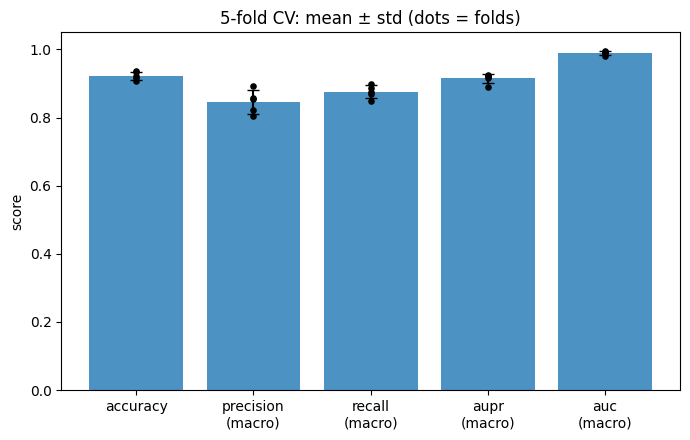


=== 5-fold CV: 65 classes, 37264 pairs (mean ± std) ===
accuracy        0.9227 ± 0.0121
precision_macro 0.8464 ± 0.0349
recall_macro    0.8760 ± 0.0188
f1_macro        0.8532 ± 0.0261
f1_weighted     0.9229 ± 0.0120
mcc             0.9077 ± 0.0143
auc_macro       0.9899 ± 0.0061
auc_weighted    0.9931 ± 0.0013
auc_micro       0.9973 ± 0.0011
aupr_macro      0.9147 ± 0.0140
aupr_weighted   0.9666 ± 0.0044
aupr_micro      0.9651 ± 0.0046
Epoch   1 | train 1.8282 | val 0.7830 | acc 0.7607 | macroF1 0.6382 | lr 1.0e-03
Epoch   2 | train 0.9532 | val 0.6553 | acc 0.7944 | macroF1 0.6996 | lr 1.0e-03
Epoch   3 | train 0.8238 | val 0.5638 | acc 0.8298 | macroF1 0.7591 | lr 1.0e-03
Epoch   4 | train 0.7669 | val 0.5351 | acc 0.8387 | macroF1 0.7717 | lr 1.0e-03
Epoch   5 | train 0.7126 | val 0.4527 | acc 0.8587 | macroF1 0.7825 | lr 1.0e-03
Epoch   6 | train 0.6713 | val 0.4212 | acc 0.8761 | macroF1 0.7755 | lr 1.0e-03
Epoch   7 | train 0.6461 | val 0.4117 | acc 0.8787 | macroF1 0.8025 | lr 

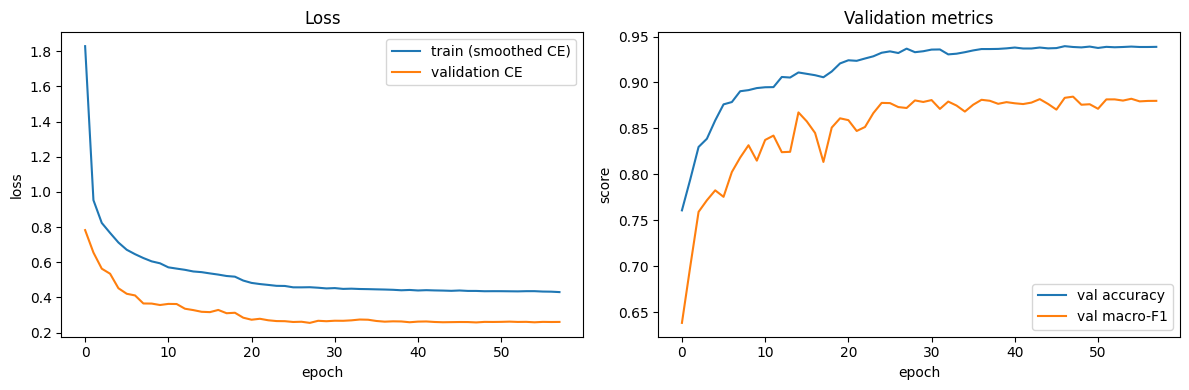

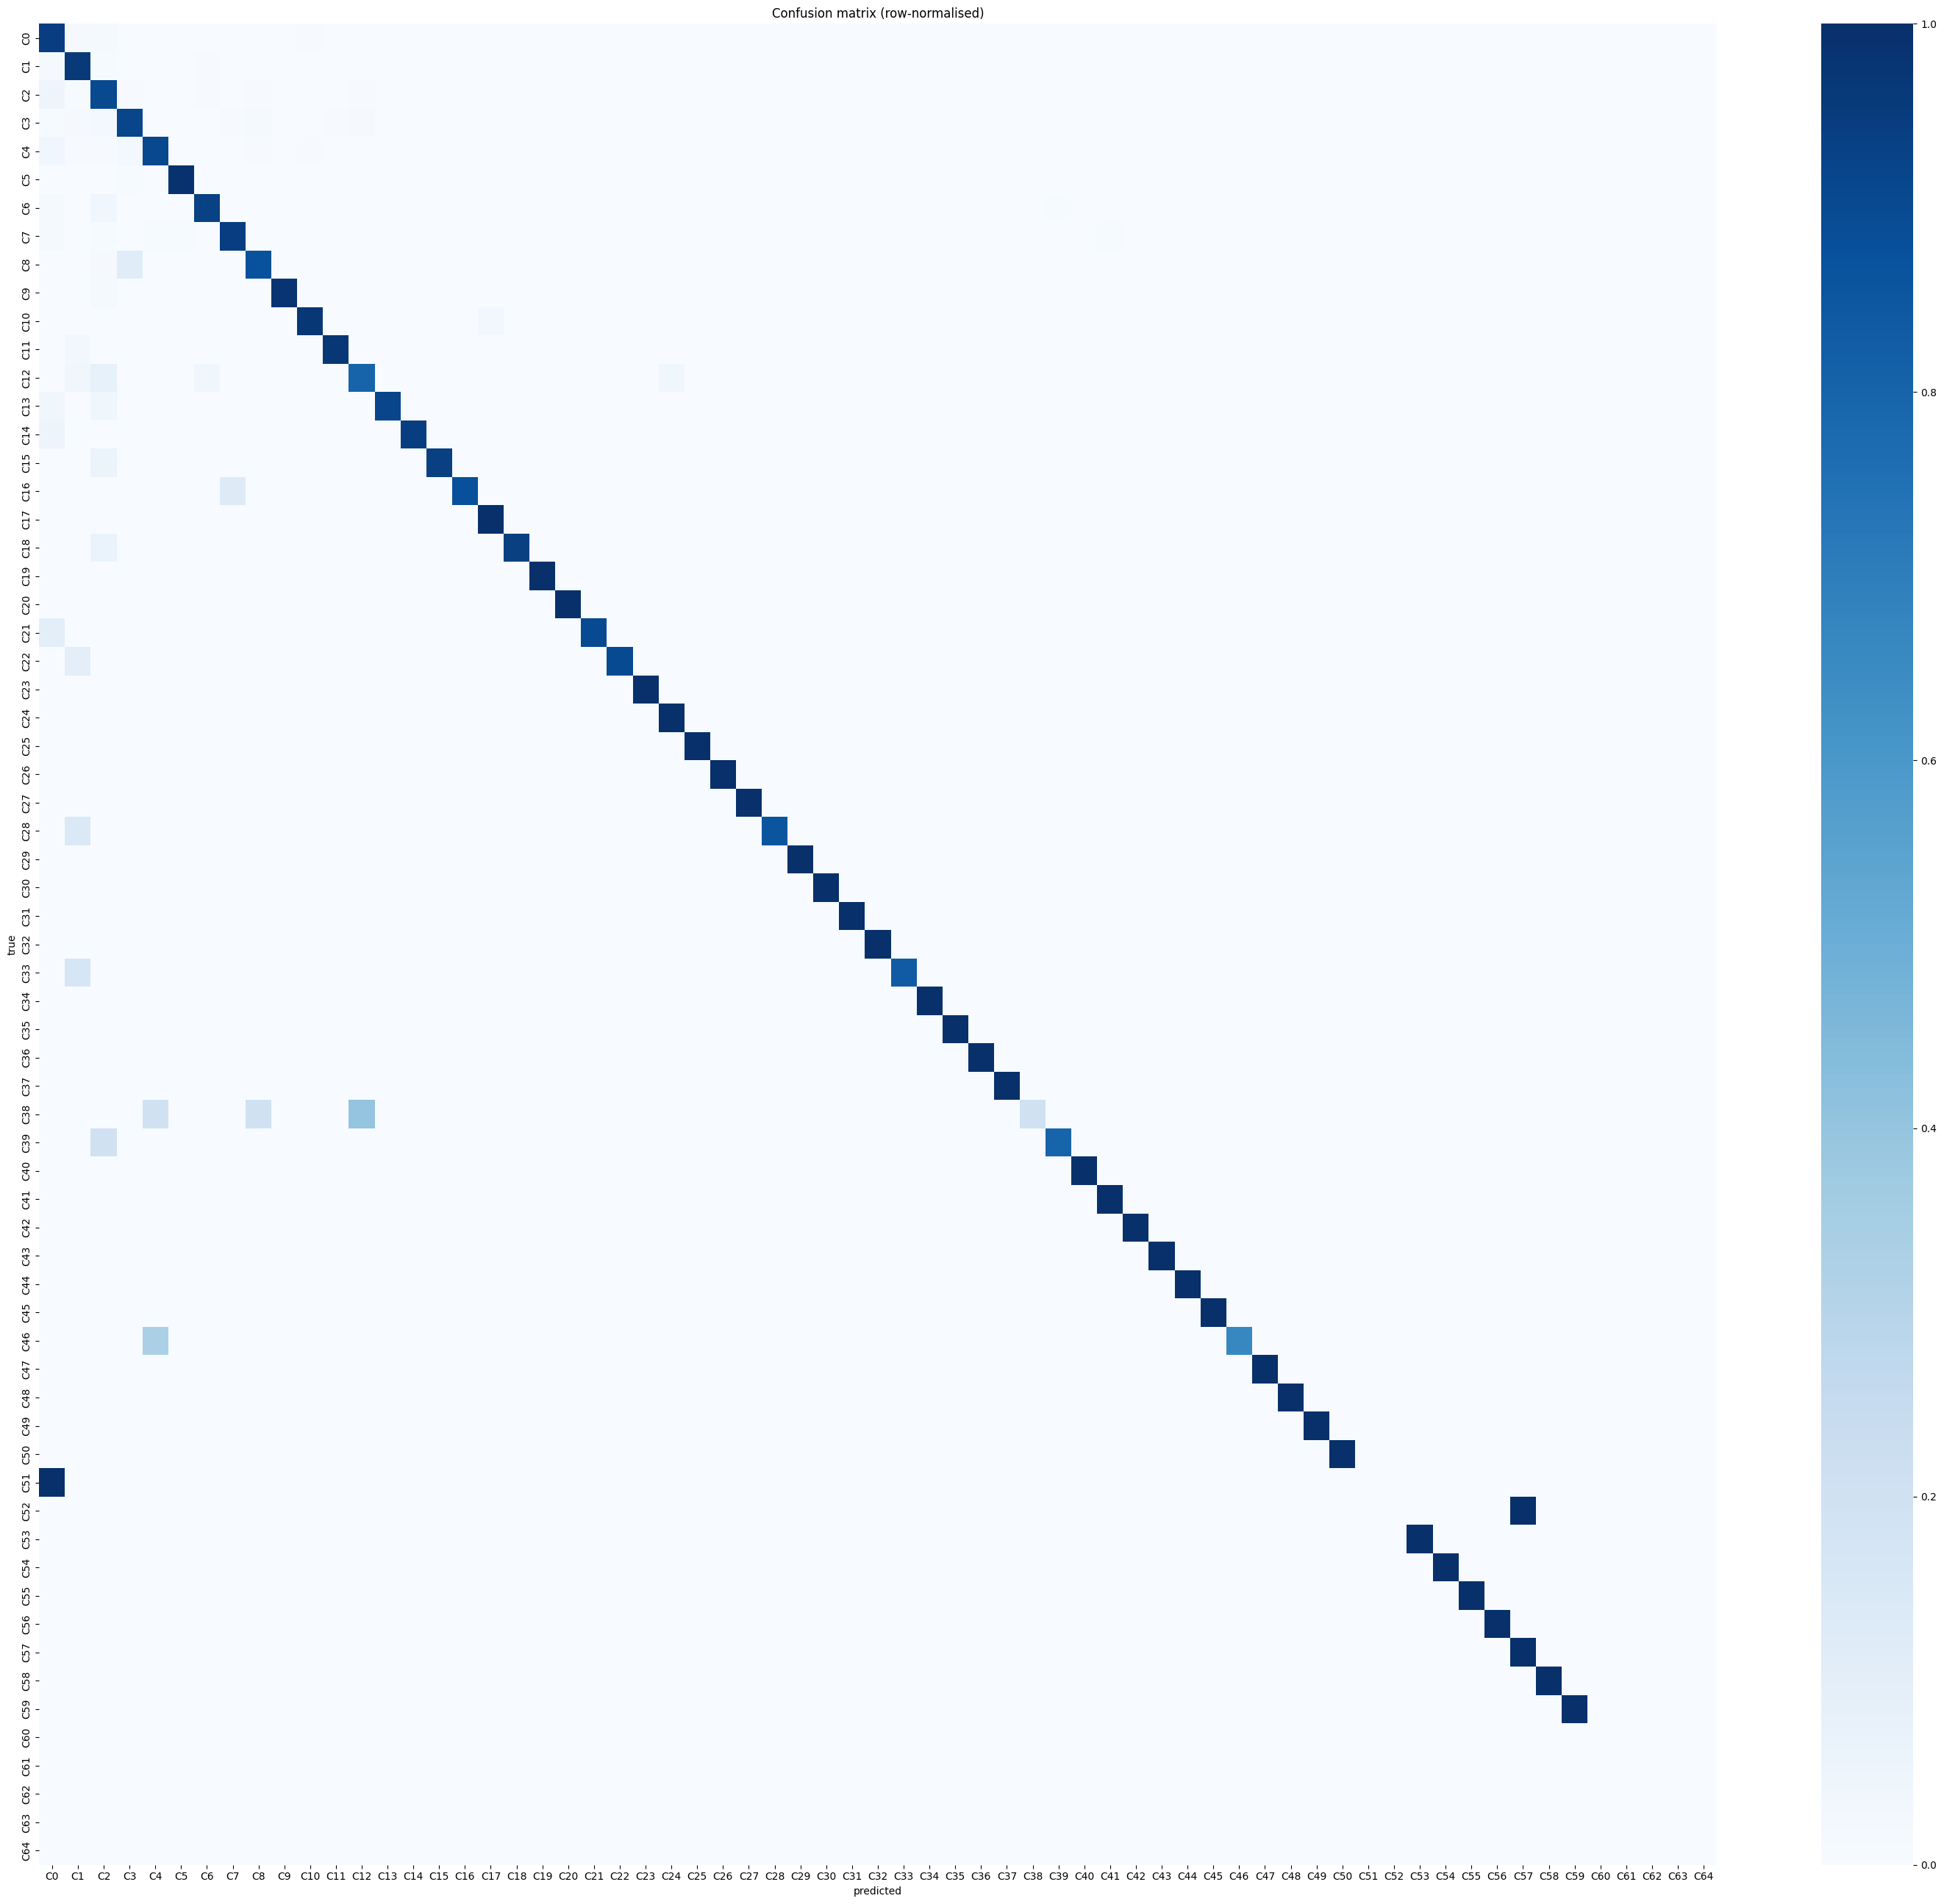

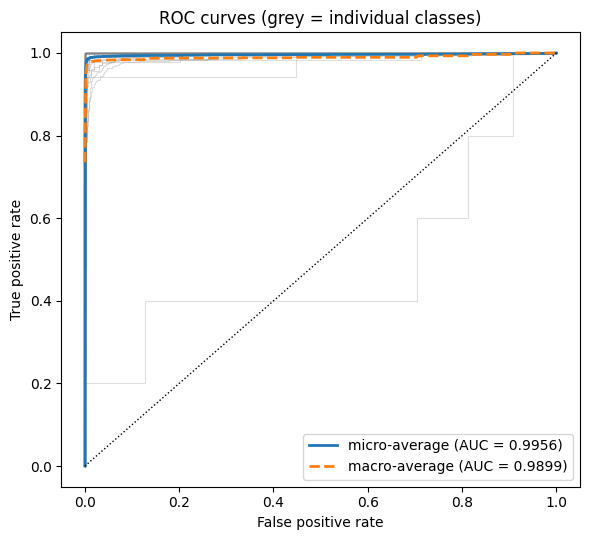

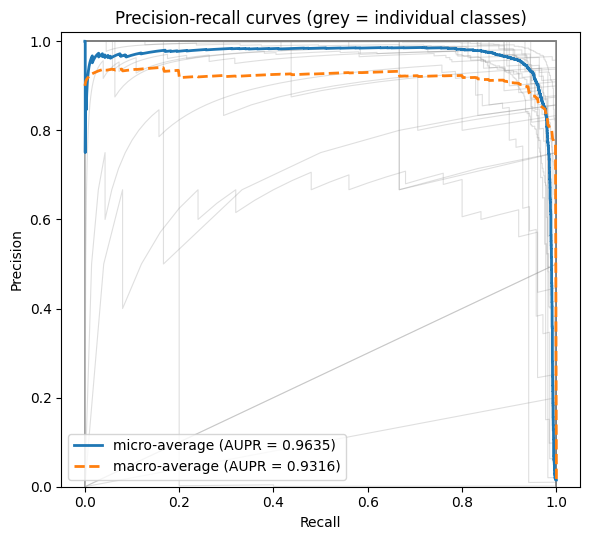

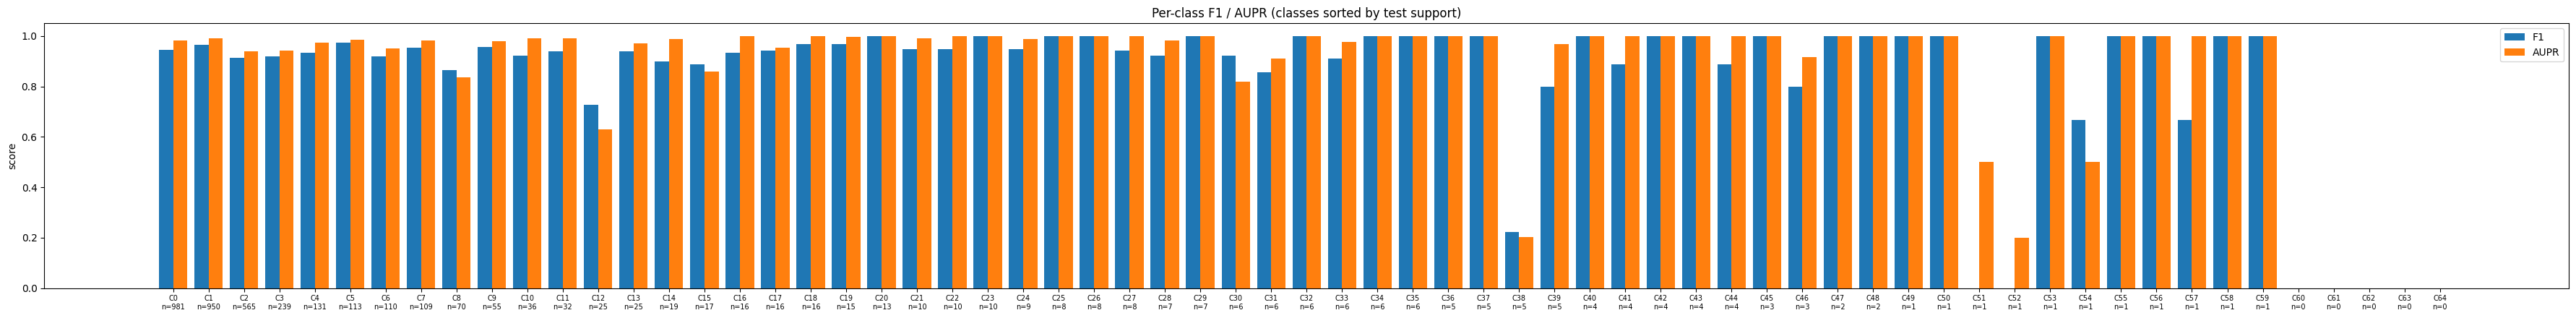

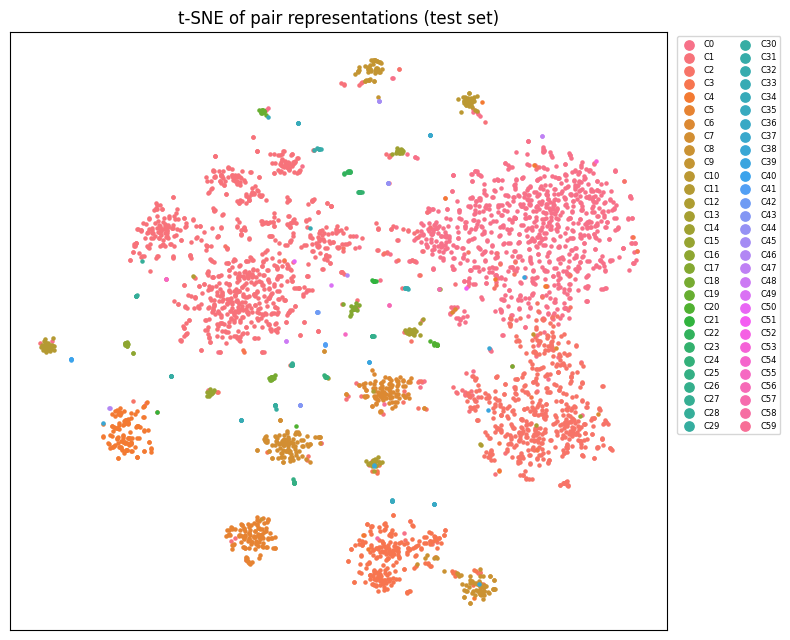

Saved model.pt, meta.json and known_pairs.npz to 'artifacts/'


In [37]:
def save_artifacts(model, data, out_dir="artifacts", metrics=None, model_config=None):
    os.makedirs(out_dir, exist_ok=True)
    cfg = {**MODEL_CONFIG, **(model_config or {})}
    torch.save({k: v.cpu() for k, v in model.state_dict().items()},
               os.path.join(out_dir, "model.pt"))
    meta = {
        "drug_ids": data.drug_ids,
        "drug_names": data.drug_names,
        "class_names": data.class_names,
        "num_classes": data.K,
        "view_dims": {n: int(x.shape[1]) for n, x in data.drug_views.items()},
        "model_config": cfg,
        "test_metrics": {k: float(v) for k, v in (metrics or {}).items()},
    }
    with open(os.path.join(out_dir, "meta.json"), "w") as fh:
        json.dump(meta, fh)
    np.savez_compressed(os.path.join(out_dir, "known_pairs.npz"),
                        i1=data.i1, i2=data.i2, y=data.y)
    print(f"Saved model.pt, meta.json and known_pairs.npz to '{out_dir}/'")


def train_final(data, test_size=0.1, val_size=0.2, epochs=100, patience=10, batch_size=256,
                sampler_power=0.5, out_dir="artifacts", seed=SEED, model_config=None,
                plots=True, plots_dir="results", tsne=True):
    """Train one model on a 72/18/10 split, report test metrics and save demo files."""
    os.makedirs(out_dir, exist_ok=True)
    cfg = {**MODEL_CONFIG, **(model_config or {})}
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    tr, va, te = make_splits(data.y, test_size, val_size, seed)
    train_loader = make_loader(data.i1, data.i2, data.y, tr, batch_size, True, sampler_power)
    val_loader = make_loader(data.i1, data.i2, data.y, va, batch_size)
    test_loader = make_loader(data.i1, data.i2, data.y, te, batch_size)

    model = MMADL(data.drug_views, data.K, **cfg).to(device)
    ckpt = os.path.join(out_dir, "_best.pth")
    model, history = train_model(model, train_loader, val_loader, device, epochs=epochs,
                                 patience=patience, ckpt=ckpt)
    os.remove(ckpt)

    logits, y_true = predict_logits(model, test_loader, device)
    probs = _softmax(logits)
    metrics, per_class, Y = compute_metrics(y_true, probs, data.class_names)
    print("\n=== Test-set evaluation ===")
    for k, v in metrics.items():
        print(f"{k:<16}{v:.4f}")
    if plots:
        os.makedirs(plots_dir, exist_ok=True)
        per_class.to_csv(os.path.join(plots_dir, "per_class_metrics.csv"), index=False)
        with open(os.path.join(plots_dir, "metrics.json"), "w") as fh:
            json.dump({k: float(v) for k, v in metrics.items()}, fh, indent=2)
        make_all_plots(model, history, y_true, probs, per_class, Y, metrics,
                       data.i1[te], data.i2[te], device, plots_dir, tsne=tsne)
    save_artifacts(model, data, out_dir, metrics, cfg)
    return model, metrics
    
ddi_df = ddi_df.loc[:, ~ddi_df.columns.str.contains("Unnamed")]
ddi_df = add_labels(ddi_df, event_df)      # creates the integer `label` column

print(ddi_df[["id1", "id2", "label"]].head())
print("Labeled pairs:", len(ddi_df), "| distinct labels:", ddi_df["label"].nunique())
data = prepare(df, ddi_df, event_df, min_count=1)
cv_results, cv_summary = run_cv(data, n_splits=5)
model, metrics = train_final(data, out_dir="artifacts")